In [209]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import math
from collections import Counter



In [210]:
np.random.seed(42)

# Random Graphs and Network Processes

## Project Overview

This project investigates structural and dynamical properties of Erdős–Rényi random graphs \(G(n,p)\).

The study combines mathematical theory with computational simulation to examine how the edge probability \(p\) affects:

- degree distributions
- connected components
- giant-component formation
- full connectivity
- shortest-path distances
- random-walk exploration

The simulations are compared with theoretical results from random graph theory.

## Research Question

How does the edge probability \(p\) influence the structure and exploration of an Erdős–Rényi random graph?

## Methodology

Random graphs are generated using the Erdős–Rényi model \(G(n,p)\). For different values of \(p\), repeated simulations are used to estimate graph properties and investigate the effect of increasing edge density.

The main results are presented using numerical summaries and visualisations.

# Part 1: Graph Theory Basics

# Part 2: Erdős–Rényi Random Graphs

# Part 3: Connected Components and Giant Component

# Part 4: Connectivity Threshold

# Part 5: Shortest Paths

# Part 6: Random Walks

# Part 7: Final Investigation

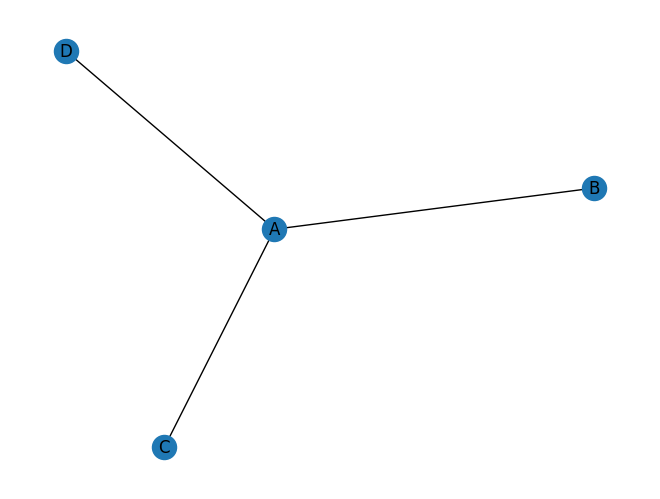

In [211]:
G = nx.Graph()

G.add_nodes_from(["A", "B", "C", "D"])

G.add_edges_from([
    ("A", "B"),
    ("A", "C"),
    ("A", "D")
])

nx.draw(G, with_labels=True)
plt.show()


### Degrees

In [212]:
print(dict(G.degree()))

{'A': 3, 'B': 1, 'C': 1, 'D': 1}


### Shortest path

In [213]:
nx.shortest_path(G, "A", "D")

['A', 'D']

In [214]:
nx.shortest_path_length(G, "A", "D")

1

### Connectivity

In [215]:
nx.is_connected(G)

True

### Disconnected Graph and Connected Components

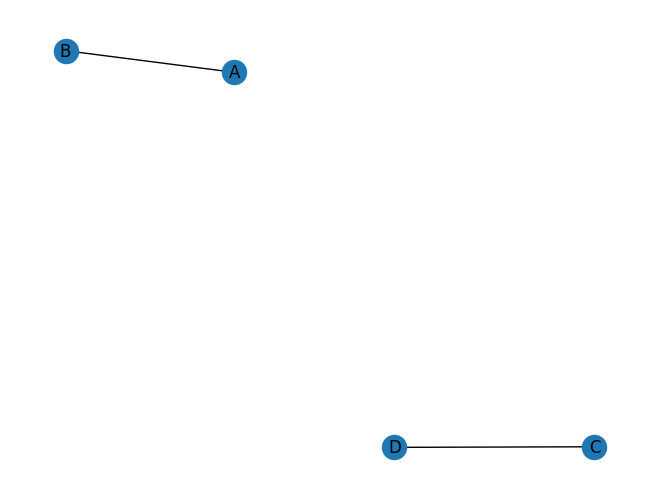

2


In [216]:
H = nx.Graph()

H.add_edges_from([
    ("A", "B"),
    ("C", "D")
])
nx.draw(H, with_labels=True)
plt.show()

print(nx.number_connected_components(H))

## Part 2: Erdős–Rényi Random Graphs

The Erdős–Rényi model G(n,p) creates a random graph with n vertices, where each possible edge is included independently with probability p.

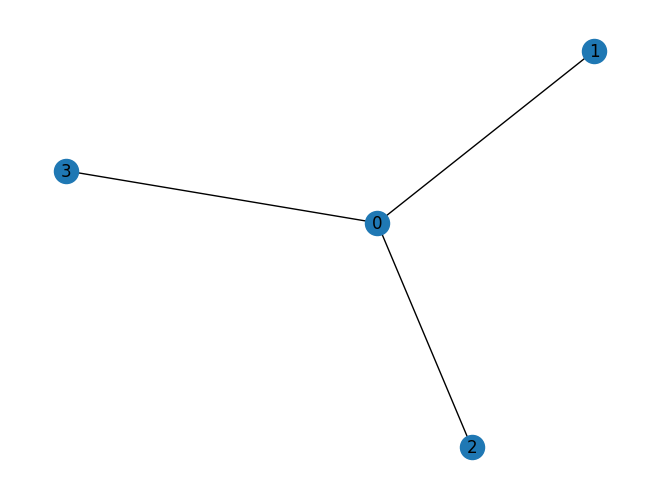

Number of vertices: 4
Number of edges: 3
Edges: [(0, 1), (0, 2), (0, 3)]
Degrees: {0: 3, 1: 1, 2: 1, 3: 1}


In [217]:
G_random = nx.erdos_renyi_graph(4, 0.5)

nx.draw(G_random, with_labels=True)
plt.show()

print("Number of vertices:", G_random.number_of_nodes())
print("Number of edges:", G_random.number_of_edges())
print("Edges:", list(G_random.edges()))
print("Degrees:", dict(G_random.degree()))

In [218]:
number_of_edges = []

for i in range(100):
    G_random = nx.erdos_renyi_graph(4, 0.5)
    number_of_edges.append(G_random.number_of_edges())

print(number_of_edges)

[4, 3, 3, 3, 2, 2, 3, 3, 3, 1, 3, 2, 2, 3, 3, 1, 1, 4, 3, 0, 5, 1, 2, 0, 1, 3, 2, 2, 2, 5, 3, 2, 5, 2, 1, 4, 4, 3, 3, 1, 1, 2, 3, 3, 5, 4, 3, 1, 4, 6, 4, 2, 3, 3, 3, 3, 3, 3, 2, 3, 3, 3, 2, 2, 5, 2, 2, 3, 4, 5, 3, 2, 2, 1, 4, 1, 5, 2, 3, 3, 3, 2, 5, 4, 5, 4, 1, 5, 0, 3, 3, 3, 3, 2, 5, 3, 3, 4, 3, 6]


In [219]:
# Generate a 100-vertex Erdős–Rényi random graph

n = 100
p = 0.03

G_degree = nx.erdos_renyi_graph(n, p)

degree_sequence = [
    degree for _, degree in G_degree.degree()
]

print("Number of vertices:", n)
print("Number of edges:", G_degree.number_of_edges())
print("Average degree:", round(np.mean(degree_sequence), 3))

Number of vertices: 100
Number of edges: 152
Average degree: 3.04


## Theoretical Degree Distribution

In the Erdős–Rényi model \(G(n,p)\), each possible edge is included independently with probability \(p\).

For a fixed vertex, there are \(n-1\) possible neighbours. Therefore, the degree of a vertex follows a binomial distribution:

\[
D \sim \mathrm{Binomial}(n-1,p)
\]

The probability that a vertex has degree \(k\) is

\[
P(D=k)
=
\binom{n-1}{k}p^k(1-p)^{n-1-k}.
\]

The expected degree is

\[
E[D]=(n-1)p.
\]

For this simulation, \(n=100\) and \(p=0.03\), so the theoretical expected degree is

\[
E[D]=99(0.03)=2.97.
\]

The simulated degree distribution can now be compared with this theoretical binomial distribution.

In [220]:


degree_counts = Counter(degree_sequence)

for degree in sorted(degree_counts):
    print(f"Degree {degree}: {degree_counts[degree]} vertices")

total_vertices = len(degree_sequence)

for degree in sorted(degree_counts):
    proportion = degree_counts[degree] / total_vertices
    print(f"Degree {degree}: {proportion:.3f}")

Degree 0: 7 vertices
Degree 1: 9 vertices
Degree 2: 21 vertices
Degree 3: 27 vertices
Degree 4: 18 vertices
Degree 5: 10 vertices
Degree 6: 7 vertices
Degree 8: 1 vertices
Degree 0: 0.070
Degree 1: 0.090
Degree 2: 0.210
Degree 3: 0.270
Degree 4: 0.180
Degree 5: 0.100
Degree 6: 0.070
Degree 8: 0.010


In [221]:

total_vertices = n
p_simulation = p

print("Simulation probability p:", p_simulation)
print("Theoretical expected degree:", (n - 1) * p_simulation)

theoretical_distribution = {}

for degree in sorted(degree_counts):

    probability = (
        math.comb(total_vertices - 1, degree)
        * (p_simulation ** degree)
        * ((1 - p_simulation) ** (total_vertices - 1 - degree))
    )

    theoretical_distribution[degree] = probability

    print(
        f"Degree {degree}: "
        f"Observed = {degree_counts[degree] / total_vertices:.3f}, "
        f"Theoretical = {probability:.3f}"
    )

Simulation probability p: 0.03
Theoretical expected degree: 2.9699999999999998
Degree 0: Observed = 0.070, Theoretical = 0.049
Degree 1: Observed = 0.090, Theoretical = 0.150
Degree 2: Observed = 0.210, Theoretical = 0.227
Degree 3: Observed = 0.270, Theoretical = 0.227
Degree 4: Observed = 0.180, Theoretical = 0.169
Degree 5: Observed = 0.100, Theoretical = 0.099
Degree 6: Observed = 0.070, Theoretical = 0.048
Degree 8: Observed = 0.010, Theoretical = 0.007


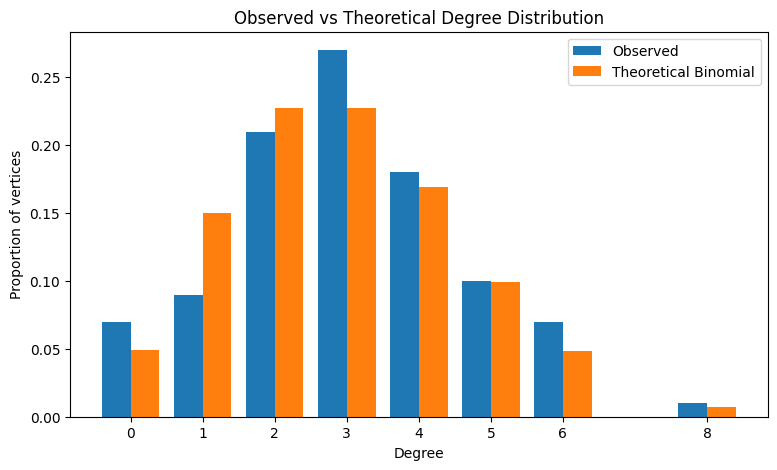

In [222]:


degrees = sorted(degree_counts)

observed = [
    degree_counts[d] / total_vertices
    for d in degrees
]

theoretical = [
    theoretical_distribution[d]
    for d in degrees
]

plt.figure(figsize=(9, 5))

plt.bar(
    [d - 0.2 for d in degrees],
    observed,
    width=0.4,
    label="Observed"
)

plt.bar(
    [d + 0.2 for d in degrees],
    theoretical,
    width=0.4,
    label="Theoretical Binomial"
)

plt.xlabel("Degree")
plt.ylabel("Proportion of vertices")
plt.title("Observed vs Theoretical Degree Distribution")
plt.xticks(degrees)
plt.legend()
plt.show()

In [223]:



num_simulations = 100
n = 100
p = p_simulation

all_average_degrees = []

for i in range(num_simulations):

    G_sim = nx.erdos_renyi_graph(n, p)

    degrees_sim = [degree for _, degree in G_sim.degree()]

    average_degree = sum(degrees_sim) / n

    all_average_degrees.append(average_degree)

print("Number of simulations:", num_simulations)
print("Number of vertices per graph:", n)
print("Probability p:", round(p, 4))

print(
    "Mean average degree across simulations:",
    round(np.mean(all_average_degrees), 3)
)

print(
    "Standard deviation:",
    round(np.std(all_average_degrees), 3)
)

Number of simulations: 100
Number of vertices per graph: 100
Probability p: 0.03
Mean average degree across simulations: 2.977
Standard deviation: 0.239


## Interpretation

For an Erdős–Rényi graph \(G(n,p)\), the theoretical expected degree is

\[
E[D]=(n-1)p.
\]

The simulation calculates the average degree across 100 independently generated random graphs. The mean simulated average degree should be close to the theoretical expected degree, with some variation due to randomness.

The standard deviation measures how much the average degree varies between simulations.

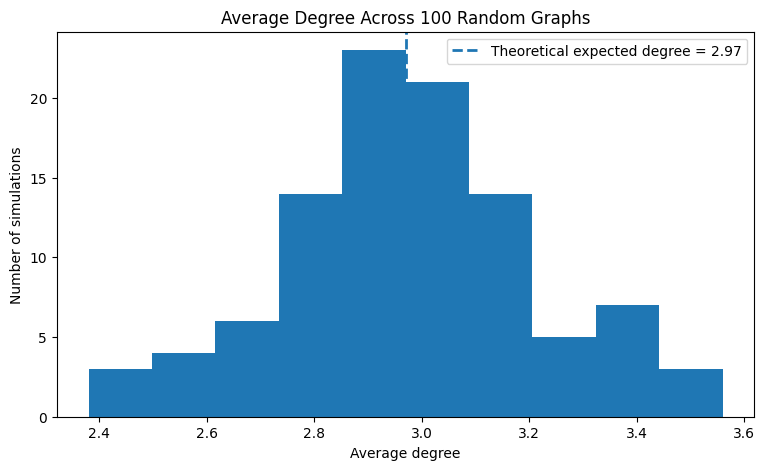

In [224]:


expected_degree = (n - 1) * p

plt.figure(figsize=(9, 5))

plt.hist(all_average_degrees, bins=10)

plt.axvline(
    expected_degree,
    linestyle="--",
    linewidth=2,
    label=f"Theoretical expected degree = {expected_degree:.2f}"
)

plt.xlabel("Average degree")
plt.ylabel("Number of simulations")
plt.title("Average Degree Across 100 Random Graphs")
plt.legend()

plt.show()

# Part 3: Connected Components and Giant Component

### 3.0 Connected Components in One Random Graph

In [225]:

# Generate one 100-vertex random graph

n = 100
p = 0.03

G_100 = nx.erdos_renyi_graph(n, p)

print("Number of vertices:", G_100.number_of_nodes())
print("Number of edges:", G_100.number_of_edges())

Number of vertices: 100
Number of edges: 152


In [226]:
# Find connected components

components = list(nx.connected_components(G_100))

# Sort from largest to smallest
components = sorted(components, key=len, reverse=True)

print("Number of connected components:", len(components))

print("\nComponent sizes:")
for i, component in enumerate(components, 1):
    print(f"Component {i}: {len(component)} vertices")

Number of connected components: 7

Component sizes:
Component 1: 94 vertices
Component 2: 1 vertices
Component 3: 1 vertices
Component 4: 1 vertices
Component 5: 1 vertices
Component 6: 1 vertices
Component 7: 1 vertices


## Interpretation

A single \(G(100,p)\) simulation can contain multiple connected components.

The component sizes show how the 100 vertices are distributed among these components. Because the graph is random, the number and sizes of the components can vary between simulations.

The largest component is particularly important because its size helps us study the emergence of large-scale connectivity in random graphs.


## 3.1 Repeated Simulation of the Largest Component

In [227]:


num_simulations = 100
n = 100
p = 0.03

largest_component_sizes = []

for i in range(num_simulations):

    G_sim = nx.erdos_renyi_graph(n, p)

    components = nx.connected_components(G_sim)

    largest_component = max(components, key=len)

    largest_component_sizes.append(len(largest_component))

print("Number of simulations:", num_simulations)
print("Number of vertices per graph:", n)
print("Probability p:", round(p, 4))

print(
    "Mean largest component size:",
    round(np.mean(largest_component_sizes), 2)
)

print(
    "Standard deviation:",
    round(np.std(largest_component_sizes), 2)
)

print(
    "Minimum largest component size:",
    min(largest_component_sizes)
)

print(
    "Maximum largest component size:",
    max(largest_component_sizes)
)

Number of simulations: 100
Number of vertices per graph: 100
Probability p: 0.03
Mean largest component size: 94.29
Standard deviation: 2.87
Minimum largest component size: 88
Maximum largest component size: 100


### Interpretation

Across 100 independent simulations, the mean, standard deviation, minimum, and maximum largest-component sizes are reported above.

These statistics describe the variability in the size of the largest connected component for \(G(100,p)\).

The variation between simulations is expected because the edges are generated randomly.

### 3.2 Effect of p on the Largest Connected Component

In [228]:



num_simulations = 100
n = 100

p_values = [0.01, 0.02, 0.03, 0.04, 0.05]

mean_largest_components = []

for p in p_values:

    largest_component_sizes = []

    for i in range(num_simulations):

        G_sim = nx.erdos_renyi_graph(n, p)

        components = nx.connected_components(G_sim)

        largest_component = max(components, key=len)

        largest_component_sizes.append(len(largest_component))

    mean_size = np.mean(largest_component_sizes)

    mean_largest_components.append(mean_size)

    print(
        "p =", p,
        "| Expected degree =", round((n - 1) * p, 2),
        "| Mean largest component  =",
        round(mean_size, 2)
    )

p = 0.01 | Expected degree = 0.99 | Mean largest component  = 19.01
p = 0.02 | Expected degree = 1.98 | Mean largest component  = 78.66
p = 0.03 | Expected degree = 2.97 | Mean largest component  = 93.71
p = 0.04 | Expected degree = 3.96 | Mean largest component  = 98.12
p = 0.05 | Expected degree = 4.95 | Mean largest component  = 99.23


## Interpretation


The simulation shows how the size of the largest connected component changes as the edge probability \(p\) increases.

As \(p\) increases, the graph becomes denser and the largest connected component generally grows.

This illustrates the emergence and growth of a giant component in an Erdős–Rényi random graph. The exact component sizes vary between simulations because the graph is generated randomly.

### 3.3 Giant-Component Threshold

In [229]:


num_simulations = 100
n = 100

p_values = [0.005, 0.0075, 0.010, 0.0125, 0.015, 0.0175, 0.020]

mean_largest_components = []

for p in p_values:

    largest_component_sizes = []

    for i in range(num_simulations):

        G_sim = nx.erdos_renyi_graph(n, p)

        components = nx.connected_components(G_sim)

        largest_component = max(components, key=len)

        largest_component_sizes.append(len(largest_component))

    mean_size = np.mean(largest_component_sizes)

    mean_largest_components.append(mean_size)

    print(
        "p =", p,
        "| Expected degree =", round((n - 1) * p, 2),
        "| Mean largest component =",
        round(mean_size, 2)
    )

p = 0.005 | Expected degree = 0.49 | Mean largest component = 5.95
p = 0.0075 | Expected degree = 0.74 | Mean largest component = 10.76
p = 0.01 | Expected degree = 0.99 | Mean largest component = 18.39
p = 0.0125 | Expected degree = 1.24 | Mean largest component = 35.08
p = 0.015 | Expected degree = 1.48 | Mean largest component = 54.71
p = 0.0175 | Expected degree = 1.73 | Mean largest component = 68.86
p = 0.02 | Expected degree = 1.98 | Mean largest component = 78.97



### Interpretation

The detailed simulation examines the behaviour of the largest connected component around the theoretical giant-component threshold.

For an Erdős–Rényi graph \(G(n,p)\), the giant-component transition occurs around

\[
p \approx \frac{1}{n}.
\]

For \(n=100\),

\[
\frac{1}{n}=0.01.
\]

The simulation allows us to observe how the largest component changes around this region. Because the graphs are random and \(n\) is finite, the observed transition is not an exact single point.

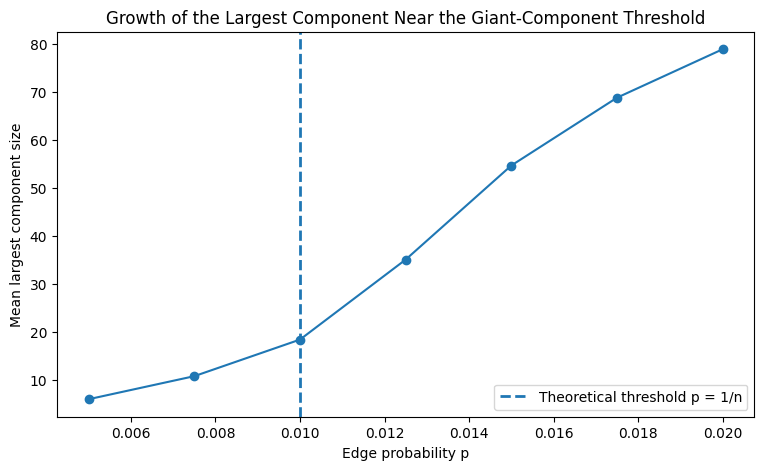

In [230]:


plt.figure(figsize=(9, 5))

plt.plot(
    p_values,
    mean_largest_components,
    marker="o"
)

plt.axvline(
    1 / n,
    linestyle="--",
    linewidth=2,
    label="Theoretical threshold p = 1/n"
)

plt.xlabel("Edge probability p")
plt.ylabel("Mean largest component size")
plt.title("Growth of the Largest Component Near the Giant-Component Threshold")
plt.legend()

plt.show()

# Part 4: Connectivity Threshold

### 4.1 Full Connectivity

In [231]:


num_simulations = 100
n = 100

p_values = [0.02, 0.03, 0.04, 0.045, 0.05, 0.055, 0.06]

connectivity_proportions = []

for p in p_values:

    connected_count = 0

    for i in range(num_simulations):

        G_sim = nx.erdos_renyi_graph(n, p)

        if nx.is_connected(G_sim):
            connected_count += 1

    proportion_connected = connected_count / num_simulations

    connectivity_proportions.append(proportion_connected)

    print(
        "p =", p,
        "| Connected graphs =",
        connected_count,
        "/",
        num_simulations,
        "| Proportion connected =",
        round(proportion_connected, 2)
    )

p = 0.02 | Connected graphs = 0 / 100 | Proportion connected = 0.0
p = 0.03 | Connected graphs = 2 / 100 | Proportion connected = 0.02
p = 0.04 | Connected graphs = 15 / 100 | Proportion connected = 0.15
p = 0.045 | Connected graphs = 35 / 100 | Proportion connected = 0.35
p = 0.05 | Connected graphs = 53 / 100 | Proportion connected = 0.53
p = 0.055 | Connected graphs = 63 / 100 | Proportion connected = 0.63
p = 0.06 | Connected graphs = 80 / 100 | Proportion connected = 0.8


## Interpretation


The simulation examines how the probability of full connectivity changes as the edge probability \(p\) increases.

For an Erdős–Rényi graph \(G(n,p)\), the connectivity threshold occurs around

\[
p \approx \frac{\log n}{n}.
\]

For \(n=100\),

\[
\frac{\log(100)}{100} \approx 0.046.
\]

As \(p\) increases through this region, fully connected graphs become increasingly likely. Since the simulations use a finite number of random graphs, the observed transition will vary between runs.

### 4.2 Full Connectivity and Largest Component Together

In [232]:


num_simulations = 100
n = 100

p_values = [0.01, 0.02, 0.03, 0.04, 0.05, 0.06]

mean_largest_components = []
connectivity_proportions = []

for p in p_values:

    largest_component_sizes = []
    connected_count = 0

    for i in range(num_simulations):

        G_sim = nx.erdos_renyi_graph(n, p)

        # Largest connected component
        components = nx.connected_components(G_sim)
        largest_component = max(components, key=len)

        largest_component_sizes.append(len(largest_component))

        # Full connectivity
        if nx.is_connected(G_sim):
            connected_count += 1

    mean_largest_component = np.mean(largest_component_sizes)
    proportion_connected = connected_count / num_simulations

    mean_largest_components.append(mean_largest_component)
    connectivity_proportions.append(proportion_connected)

    print(
        "p =", p,
        "| Mean largest component =",
        round(mean_largest_component, 2),
        "| Proportion fully connected =",
        round(proportion_connected, 2)
    )

p = 0.01 | Mean largest component = 21.1 | Proportion fully connected = 0.0
p = 0.02 | Mean largest component = 77.47 | Proportion fully connected = 0.0
p = 0.03 | Mean largest component = 94.13 | Proportion fully connected = 0.04
p = 0.04 | Mean largest component = 98.3 | Proportion fully connected = 0.24
p = 0.05 | Mean largest component = 99.35 | Proportion fully connected = 0.55
p = 0.06 | Mean largest component = 99.7 | Proportion fully connected = 0.76


### Plot 1 — Largest Component

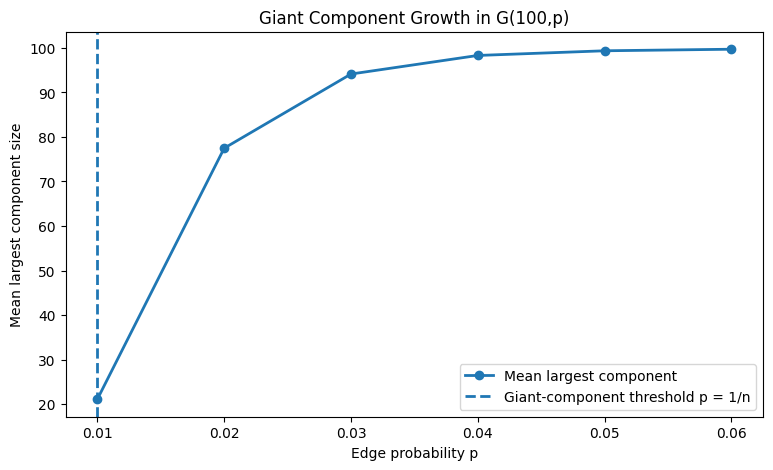

In [233]:
plt.figure(figsize=(9, 5))

plt.plot(
    p_values,
    mean_largest_components,
    marker="o",
    linewidth=2,
    label="Mean largest component"
)

plt.axvline(
    1 / n,
    linestyle="--",
    linewidth=2,
    label="Giant-component threshold p = 1/n"
)

plt.xlabel("Edge probability p")
plt.ylabel("Mean largest component size")
plt.title("Giant Component Growth in G(100,p)")
plt.legend()

plt.show()

### Plot 2 — Full Connectivity

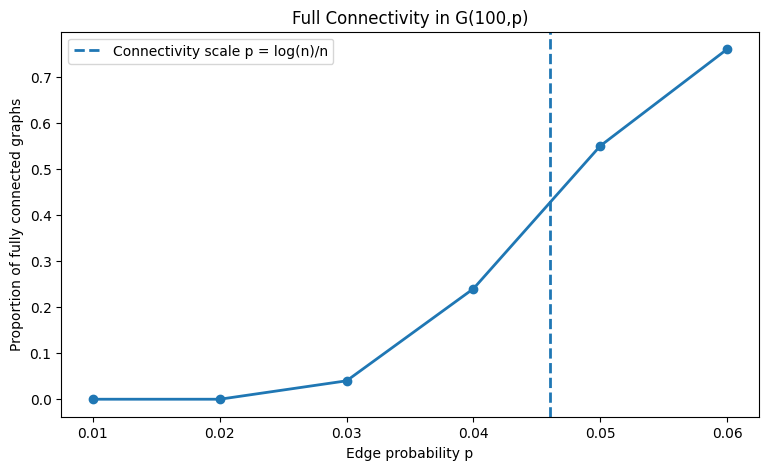

In [234]:
plt.figure(figsize=(9, 5))

plt.plot(
    p_values,
    connectivity_proportions,
    marker="o",
    linewidth=2
)

plt.axvline(
    np.log(n) / n,
    linestyle="--",
    linewidth=2,
    label="Connectivity scale p = log(n)/n"
)

plt.xlabel("Edge probability p")
plt.ylabel("Proportion of fully connected graphs")
plt.title("Full Connectivity in G(100,p)")
plt.legend()

plt.show()

### 4.3 Giant Component vs Full Connectivity

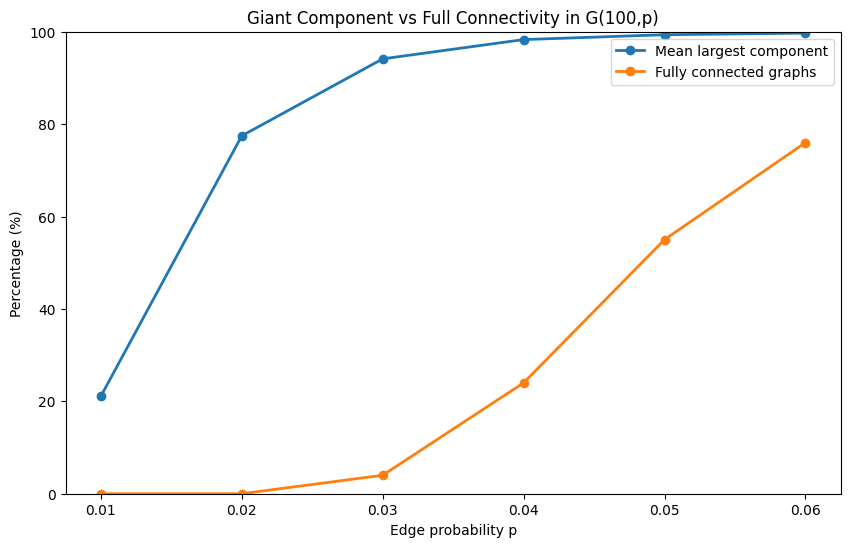

In [235]:


plt.figure(figsize=(10, 6))

# Mean largest component as percentage of vertices
largest_component_percent = [
    (size / n) * 100
    for size in mean_largest_components
]

# Fully connected graphs as percentage
connectivity_percent = [
    proportion * 100
    for proportion in connectivity_proportions
]

plt.plot(
    p_values,
    largest_component_percent,
    marker="o",
    linewidth=2,
    label="Mean largest component"
)

plt.plot(
    p_values,
    connectivity_percent,
    marker="o",
    linewidth=2,
    label="Fully connected graphs"
)

plt.xlabel("Edge probability p")
plt.ylabel("Percentage (%)")
plt.title(
    "Giant Component vs Full Connectivity in G(100,p)"
)

plt.ylim(0, 100)
plt.legend()

plt.show()

## Interpretation


The results illustrate the difference between the giant-component transition and full connectivity in an Erdős–Rényi random graph.

As \(p\) increases, the largest connected component generally becomes larger. However, having a very large connected component does not necessarily mean that the entire graph is connected.

The two theoretical scales are different:

\[
p \approx \frac{1}{n}
\]

for the emergence of a giant component, and

\[
p \approx \frac{\log n}{n}
\]

for full connectivity.

Thus, a random graph can contain a giant component while still having one or more smaller disconnected components.

# Part 5: Shortest Paths

### 5.1 Shortest Paths in a Random Graph

In [236]:


n = 100
p = 0.03

G_shortest = nx.erdos_renyi_graph(n, p)

print("Number of vertices:", G_shortest.number_of_nodes())
print("Number of edges:", G_shortest.number_of_edges())
print("Is the graph connected?", nx.is_connected(G_shortest))

Number of vertices: 100
Number of edges: 182
Is the graph connected? False


In [237]:
source = 0
target = 50

if nx.has_path(G_shortest, source, target):

    path = nx.shortest_path(
        G_shortest,
        source=source,
        target=target
    )

    distance = nx.shortest_path_length(
        G_shortest,
        source=source,
        target=target
    )

    print("Shortest path:", path)
    print("Shortest path length:", distance)

else:
    print("No path exists between these vertices.")

Shortest path: [0, 98, 66, 62, 50]
Shortest path length: 4


In [238]:
# Calculate average shortest-path length
# within the largest connected component

largest_component = max(
    nx.connected_components(G_shortest),
    key=len
)

G_largest = G_shortest.subgraph(largest_component)

average_shortest_path = nx.average_shortest_path_length(G_largest)

print("Size of largest component:", G_largest.number_of_nodes())
print("Average shortest-path length:", round(average_shortest_path, 3))

Size of largest component: 98
Average shortest-path length: 3.643


### 5.2 Effect of \(p\) on Shortest Paths

In [239]:


num_simulations = 100
n = 100

p_values_shortest = [0.02, 0.03, 0.04, 0.05, 0.06]

mean_shortest_paths = []

for p in p_values_shortest:

    shortest_path_lengths = []

    for i in range(num_simulations):

        G_sim = nx.erdos_renyi_graph(n, p)

        # Find the largest connected component
        largest_component = max(
            nx.connected_components(G_sim),
            key=len
        )

        G_largest = G_sim.subgraph(largest_component)

        # Calculate average shortest-path length
        average_path = nx.average_shortest_path_length(
            G_largest
        )

        shortest_path_lengths.append(average_path)

    mean_path = np.mean(shortest_path_lengths)

    mean_shortest_paths.append(mean_path)

    print(
        "p =", p,
        "| Mean average shortest-path length =",
        round(mean_path, 3)
    )

p = 0.02 | Mean average shortest-path length = 5.757
p = 0.03 | Mean average shortest-path length = 4.182
p = 0.04 | Mean average shortest-path length = 3.435
p = 0.05 | Mean average shortest-path length = 3.031
p = 0.06 | Mean average shortest-path length = 2.756


## Interpretation

The simulations show how average shortest-path length changes as the edge probability \(p\) increases.

As \(p\) increases, the graph becomes denser and additional edges create more possible routes between vertices. Consequently, the average shortest-path length generally decreases.

This shows how increasing edge density can reduce the typical distance between vertices in an Erdős–Rényi random graph.

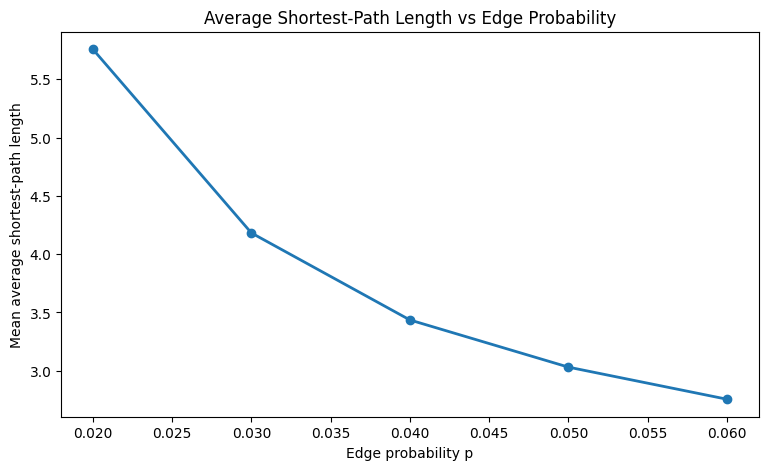

In [240]:
# Plot average shortest-path length against p

plt.figure(figsize=(9, 5))

plt.plot(
    p_values_shortest,
    mean_shortest_paths,
    marker="o",
    linewidth=2
)

plt.xlabel("Edge probability p")
plt.ylabel("Mean average shortest-path length")
plt.title("Average Shortest-Path Length vs Edge Probability")

plt.show()

### 5.3 Largest Component and Shortest Path

In [241]:
# Compare largest component size and average shortest-path length

num_simulations = 100
n = 100

p_values = [0.02, 0.03, 0.04, 0.05, 0.06]

mean_largest_components = []
mean_shortest_paths = []

for p in p_values:

    largest_sizes = []
    shortest_paths = []

    for i in range(num_simulations):

        G_sim = nx.erdos_renyi_graph(n, p)

        # Find largest connected component
        largest_component = max(
            nx.connected_components(G_sim),
            key=len
        )

        G_largest = G_sim.subgraph(largest_component)

        # Largest component size
        largest_sizes.append(
            G_largest.number_of_nodes()
        )

        # Average shortest-path length
        average_path = nx.average_shortest_path_length(
            G_largest
        )

        shortest_paths.append(average_path)

    # Average across simulations
    mean_largest = np.mean(largest_sizes)
    mean_path = np.mean(shortest_paths)

    mean_largest_components.append(mean_largest)
    mean_shortest_paths.append(mean_path)

    print(
        "p =", p,
        "| Mean largest component =",
        round(mean_largest, 2),
        "| Mean shortest path =",
        round(mean_path, 3)
    )

p = 0.02 | Mean largest component = 78.64 | Mean shortest path = 5.682
p = 0.03 | Mean largest component = 93.71 | Mean shortest path = 4.137
p = 0.04 | Mean largest component = 98.3 | Mean shortest path = 3.401
p = 0.05 | Mean largest component = 99.37 | Mean shortest path = 3.021
p = 0.06 | Mean largest component = 99.74 | Mean shortest path = 2.755


## Interpretation

The simulation combines two structural properties of the random graph.

As the edge probability \(p\) increases, the largest connected component generally grows, while the average shortest-path length generally decreases.

This demonstrates that increasing edge density affects both the size of the connected structure and the typical distance between vertices.

# Part 6: Random Walks

### 6.1 Random Walk on a Random Graph

In [242]:


n = 100
p = 0.03

G_walk = nx.erdos_renyi_graph(n, p)

# Starting vertex
current_vertex = 0

# Number of steps
num_steps = 20

walk = [current_vertex]

for step in range(num_steps):

    neighbours = list(G_walk.neighbors(current_vertex))

    if len(neighbours) == 0:
        print("The walk stopped because the vertex has no neighbours.")
        break

    current_vertex = np.random.choice(neighbours)

    walk.append(current_vertex)

print("Random walk:")
print(walk)

print("Number of steps completed:", len(walk) - 1)

Random walk:
[0, np.int64(48), np.int64(27), np.int64(48), np.int64(27), np.int64(48), np.int64(27), np.int64(75), np.int64(94), np.int64(54), np.int64(94), np.int64(54), np.int64(94), np.int64(75), np.int64(82), np.int64(49), np.int64(82), np.int64(75), np.int64(27), np.int64(53), np.int64(27)]
Number of steps completed: 20


### 6.2 A 100-Step Random Walk

In [243]:


n = 100
p = 0.03
num_steps = 100

G_walk = nx.erdos_renyi_graph(n, p)

current_vertex = 0
walk = [current_vertex]

for step in range(num_steps):

    neighbours = list(G_walk.neighbors(current_vertex))

    if len(neighbours) == 0:
        break

    current_vertex = np.random.choice(neighbours)
    walk.append(current_vertex)

unique_vertices = set(walk)

print("Number of steps completed:", len(walk) - 1)
print("Number of unique vertices visited:", len(unique_vertices))
print("Percentage of graph visited:",
      round(len(unique_vertices) / n * 100, 2), "%")

Number of steps completed: 100
Number of unique vertices visited: 39
Percentage of graph visited: 39.0 %


### 6.3 Repeated Random-Walk Simulations

In [244]:


n = 100
p = 0.03

num_simulations = 100
num_steps = 100

unique_vertices_counts = []

for i in range(num_simulations):

    G_walk = nx.erdos_renyi_graph(n, p)

    current_vertex = 0
    visited = {current_vertex}

    for step in range(num_steps):

        neighbours = list(G_walk.neighbors(current_vertex))

        if len(neighbours) == 0:
            break

        current_vertex = np.random.choice(neighbours)
        visited.add(current_vertex)

    unique_vertices_counts.append(len(visited))


print("Number of simulations:", num_simulations)
print("Number of steps per walk:", num_steps)
print(
    "Mean number of unique vertices visited:",
    round(np.mean(unique_vertices_counts), 2)
)
print(
    "Standard deviation:",
    round(np.std(unique_vertices_counts), 2)
)
print(
    "Mean percentage of graph visited:",
    round(np.mean(unique_vertices_counts) / n * 100, 2),
    "%"
)

Number of simulations: 100
Number of steps per walk: 100
Mean number of unique vertices visited: 38.58
Standard deviation: 12.93
Mean percentage of graph visited: 38.58 %


## Interpretation

Across the simulations, the mean and standard deviation of the number of unique vertices visited are reported above.

A random walk can revisit vertices that it has already visited, so the number of unique vertices is generally smaller than the number of steps.

The variation between simulations reflects the randomness of both the graph structure and the movement of the random walk.

### 6.4 Effect of \(p\) on Random-Walk Exploration

In [245]:


n = 100
num_simulations = 100
num_steps = 100

p_values = [0.01, 0.02, 0.03, 0.04, 0.05]

mean_unique_vertices = []

for p in p_values:

    unique_vertices_counts = []

    for i in range(num_simulations):

        G_walk = nx.erdos_renyi_graph(n, p)

        current_vertex = 0
        visited = {current_vertex}

        for step in range(num_steps):

            neighbours = list(G_walk.neighbors(current_vertex))

            if len(neighbours) == 0:
                break

            current_vertex = np.random.choice(neighbours)
            visited.add(current_vertex)

        unique_vertices_counts.append(len(visited))

    mean_unique_vertices.append(np.mean(unique_vertices_counts))


print("Results:")
print()

for p, mean in zip(p_values, mean_unique_vertices):

    print(
        "p =", p,
        "| Mean unique vertices visited =", round(mean, 2),
        "| Percentage visited =", round(mean / n * 100, 2), "%"
    )

Results:

p = 0.01 | Mean unique vertices visited = 4.48 | Percentage visited = 4.48 %
p = 0.02 | Mean unique vertices visited = 24.6 | Percentage visited = 24.6 %
p = 0.03 | Mean unique vertices visited = 37.8 | Percentage visited = 37.8 %
p = 0.04 | Mean unique vertices visited = 48.2 | Percentage visited = 48.2 %
p = 0.05 | Mean unique vertices visited = 49.53 | Percentage visited = 49.53 %


## Interpretation

The simulation shows how edge probability \(p\) affects random-walk exploration.

As \(p\) increases, the graph becomes denser and the random walk generally has access to more neighbouring vertices. This allows the walk to explore a larger portion of the network.

The results demonstrate a relationship between graph density and the exploration behaviour of random walks.

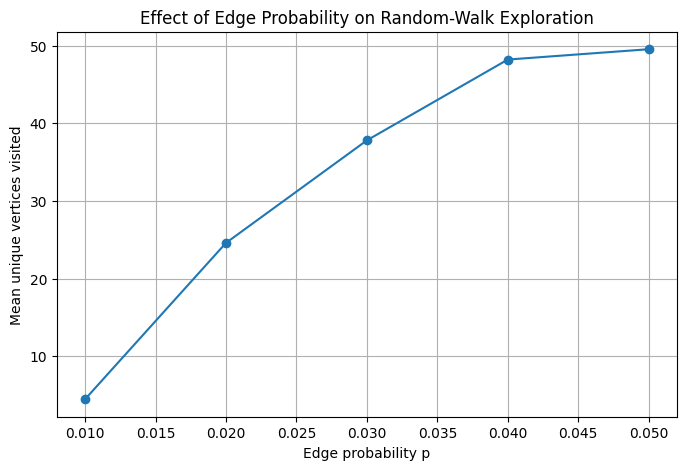

In [246]:


plt.figure(figsize=(8, 5))

plt.plot(
    p_values,
    mean_unique_vertices,
    marker="o"
)

plt.xlabel("Edge probability p")
plt.ylabel("Mean unique vertices visited")
plt.title("Effect of Edge Probability on Random-Walk Exploration")

plt.grid(True)
plt.show()

# Part 7: Final Investigation

### 7.1 Final Simulation

In [247]:
n = 100
num_simulations = 100
num_steps = 100

p_values = [0.01, 0.02, 0.03, 0.04, 0.05, 0.06]

mean_largest_component = []
mean_shortest_path = []
mean_unique_visited = []

for p in p_values:

    largest_sizes = []
    shortest_paths = []
    unique_vertices = []

    for i in range(num_simulations):

        # Generate random graph
        G = nx.erdos_renyi_graph(n, p)

        # Find largest connected component
        components = list(nx.connected_components(G))
        largest_component = max(components, key=len)

        G_largest = G.subgraph(largest_component)

        largest_sizes.append(len(largest_component))

        # Average shortest path
        if len(G_largest) > 1:
            shortest_paths.append(
                nx.average_shortest_path_length(G_largest)
            )

        # Random walk
        current_vertex = np.random.choice(
            list(G_largest.nodes)
        )

        visited = {current_vertex}

        for step in range(num_steps):

            neighbours = list(
                G_largest.neighbors(current_vertex)
            )

            if len(neighbours) == 0:
                break

            current_vertex = np.random.choice(
                neighbours
            )

            visited.add(current_vertex)

        unique_vertices.append(len(visited))

    mean_largest_component.append(
        np.mean(largest_sizes)
    )

    mean_shortest_path.append(
        np.mean(shortest_paths)
    )

    mean_unique_visited.append(
        np.mean(unique_vertices)
    )

### 7.2 Final Results

In [248]:
print("Final Investigation Results")
print()

for i, p in enumerate(p_values):

    print(
        "p =", p,
        "| Largest component =",
        round(mean_largest_component[i], 2),
        "| Avg shortest path =",
        round(mean_shortest_path[i], 2),
        "| Unique vertices visited =",
        round(mean_unique_visited[i], 2)
    )

Final Investigation Results

p = 0.01 | Largest component = 19.46 | Avg shortest path = 4.1 | Unique vertices visited = 13.96
p = 0.02 | Largest component = 79.82 | Avg shortest path = 5.55 | Unique vertices visited = 29.93
p = 0.03 | Largest component = 94.34 | Avg shortest path = 4.16 | Unique vertices visited = 41.59
p = 0.04 | Largest component = 98.02 | Avg shortest path = 3.44 | Unique vertices visited = 49.34
p = 0.05 | Largest component = 99.4 | Avg shortest path = 3.03 | Unique vertices visited = 52.03
p = 0.06 | Largest component = 99.8 | Avg shortest path = 2.75 | Unique vertices visited = 54.18


### 7.3 Connectivity and Random-Walk Exploration

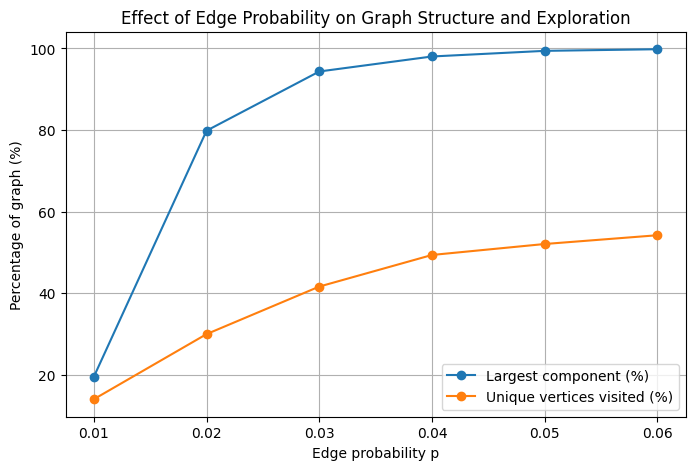

In [249]:


largest_component_percentage = [
    value / n * 100 for value in mean_largest_component
]

unique_visited_percentage = [
    value / n * 100 for value in mean_unique_visited
]

plt.figure(figsize=(8, 5))

plt.plot(
    p_values,
    largest_component_percentage,
    marker="o",
    label="Largest component (%)"
)

plt.plot(
    p_values,
    unique_visited_percentage,
    marker="o",
    label="Unique vertices visited (%)"
)

plt.xlabel("Edge probability p")
plt.ylabel("Percentage of graph (%)")
plt.title("Effect of Edge Probability on Graph Structure and Exploration")

plt.legend()
plt.grid(True)

plt.show()

### 7.4 Average Shortest-Path Length

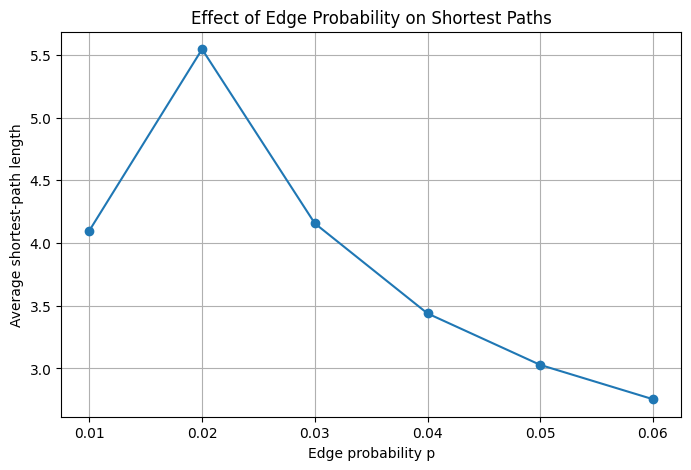

In [250]:


plt.figure(figsize=(8, 5))

plt.plot(
    p_values,
    mean_shortest_path,
    marker="o"
)

plt.xlabel("Edge probability p")
plt.ylabel("Average shortest-path length")
plt.title("Effect of Edge Probability on Shortest Paths")

plt.grid(True)

plt.show()

### 7.5 Final Interpretation



Increasing the edge probability \(p\) changes several structural and behavioural properties of an Erdős–Rényi random graph.

As \(p\) increases, the largest connected component grows, average shortest-path lengths generally decrease, and random walks can visit more unique vertices.

These results show how a single probability parameter can influence connectivity, distances, and exploration in a random network.

# Conclusion

This investigation used computational simulations to study how the edge probability \(p\) affects Erdős–Rényi random graphs.

The results showed that increasing \(p\):

- increases the expected degree of vertices;
- causes the largest connected component to grow;
- increases the likelihood of full connectivity;
- generally decreases average shortest-path length;
- allows random walks to explore more of the network.

The simulations also demonstrated the distinction between the emergence of a giant component and full graph connectivity. The giant-component transition occurs around \(p \approx 1/n\), while full connectivity occurs at the larger scale \(p \approx \log(n)/n\).

Overall, the project demonstrates how theoretical results from random graph theory can be investigated and illustrated through computational experiments.

## Limitations and Future Work

The simulations use \(n=100\) vertices and a finite number of repetitions. Therefore, the observed transitions may differ from the theoretical behaviour expected for very large graphs.

The results could be extended by:

- increasing the number of vertices;
- increasing the number of simulations;
- examining larger ranges of \(p\);
- comparing different random graph models;
- studying the effect of graph size \(n\) on the observed thresholds.